# Abalone: baseline and model comparison
**Goal:** predict Rings from measurements. Compare candidates on validation data,
then refit the chosen pipeline on train + validation and evaluate on test once.
MLflow stores parameters, metrics and fitted pipelines locally; its data is ignored
by Git. The CSV is included in the repository at `data/abalone.csv`. No external tracking service is used.

In [1]:
import hashlib
import json
import subprocess
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from IPython.display import display
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

/Users/yunxianliu/MLOPS_ARTEFACT_project/.venv/lib/python3.11/site-packages/mlflow/utils/requirements_utils.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # noqa: TID251


In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "abalone.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place abalone.csv in the project's data directory.")
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
EXPECTED_COLUMNS = [
    "Sex",
    "Length",
    "Diameter",
    "Height",
    "Whole weight",
    "Shucked weight",
    "Viscera weight",
    "Shell weight",
    "Rings",
]
assert list(df.columns) == EXPECTED_COLUMNS, "Unexpected dataset columns"
assert df["Rings"].notna().all(), "The target must not contain missing values"
assert df["Rings"].gt(0).all(), "Ring counts must be positive"
assert set(df["Sex"].dropna().unique()).issubset({"M", "F", "I"})
print(f"Rows: {len(df):,}; columns: {len(df.columns)}")
print(f"Data SHA-256: {DATA_SHA256}")

Rows: 4,177; columns: 9
Data SHA-256: 6fda3c4b0c0cff9bd5f7a46434509179069ed620c8fc7090d872a08d2c1a729a


## 1. Same reproducible split as EDA

In [3]:
SEED = 42
X = df.drop(columns="Rings").copy()
y = df["Rings"].copy()
# The saved pipeline handles zero heights and learns imputation from training data.
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")

Train: 2505, validation: 836, test: 836


## 2. Preprocessing
Zero Height is converted to missing inside the pipeline. Numerical features:
median imputation, then standardization. Categorical feature:
most-frequent imputation, then one-hot encoding. All learned statistics are fitted
inside each pipeline on training data only. The saved model includes preprocessing.

In [4]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
numeric = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric, numeric_columns),
        ("categorical", categorical, ["Sex"]),
    ]
)
candidates = {
    "mean_baseline": DummyRegressor(strategy="mean"),
    "linear_regression": LinearRegression(),
    "random_forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=3,
        random_state=SEED,
        n_jobs=2,
    ),
}


def scores(target, prediction):
    return {
        "mae": float(mean_absolute_error(target, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(target, prediction))),
        "r2": float(r2_score(target, prediction)),
    }

## 3. Local MLflow experiment

In [5]:
TRACKING_DIR = ROOT / "mlruns"
TRACKING_DIR.mkdir(exist_ok=True)
mlflow.set_tracking_uri(TRACKING_DIR.as_uri())
mlflow.set_experiment("abalone_step1")
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip()
worktree_dirty = bool(
    subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip()
)
print("Experiment: abalone_step1; local MLflow tracking configured")

Experiment: abalone_step1; local MLflow tracking configured


In [6]:
results = []
fitted_models = {}
for name, estimator in candidates.items():
    model = Pipeline(
        [
            (
                "clean_height",
                FunctionTransformer(
                    pd.DataFrame.replace,
                    kw_args={"to_replace": {"Height": {0.0: np.nan}}},
                    validate=False,
                    feature_names_out="one-to-one",
                ),
            ),
            ("preprocess", clone(preprocessor)),
            ("regressor", clone(estimator)),
        ]
    )
    with mlflow.start_run(run_name=name) as run:
        mlflow.set_tags(
            {
                "phase": "validation",
                "git_commit": commit,
                "worktree_dirty": str(worktree_dirty),
            }
        )
        mlflow.log_params(
            {
                "candidate": name,
                "split_seed": SEED,
                "data_sha256": DATA_SHA256,
                "train_rows": len(X_train),
                "validation_rows": len(X_val),
                "target": "Rings",
                **estimator.get_params(),
            }
        )
        model.fit(X_train, y_train)
        train_metrics = scores(y_train, model.predict(X_train))
        validation_metrics = scores(y_val, model.predict(X_val))
        mlflow.log_metrics({f"train_{key}": val for key, val in train_metrics.items()})
        mlflow.log_metrics({f"val_{key}": val for key, val in validation_metrics.items()})
        example = X_train.head(3)
        mlflow.sklearn.log_model(
            model,
            "model",
            input_example=example,
            signature=infer_signature(example, model.predict(example)),
        )
        results.append({"model": name, **validation_metrics, "run_id": run.info.run_id})
        fitted_models[name] = model

comparison = pd.DataFrame(results).set_index("model").sort_values("mae")
display(comparison)
best_name = comparison.index[0]
print(f"Selected by validation MAE: {best_name}")

2026/10/22 10:00:34 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


/Users/yunxianliu/MLOPS_ARTEFACT_project/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
2026/10/22 10:00:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


/Users/yunxianliu/MLOPS_ARTEFACT_project/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
2026/10/22 10:00:38 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


,mae,rmse,r2,run_id
model,,,,
random_forest,1.534637,2.126378,0.548016,068d09dcc2e3461d9725f6ec76d9eba3
linear_regression,1.638637,2.423208,0.413019,b252796523e04700a43bd9f6b2c0ac97
mean_baseline,2.301327,3.168613,-0.003646,d7f2e533f4014c98a2ea0c405bf04044


Selected by validation MAE: random_forest


## 4. Final held-out test
Freeze the chosen configuration. Refit on train + validation, then evaluate it and
the mean baseline on test. Test results must not be used for further selection.
The baseline mean is also refitted on train + validation for a fair comparison.

In [7]:
final_model = clone(fitted_models[best_name]).fit(X_trainval, y_trainval)
test_prediction = final_model.predict(X_test)
test_metrics = scores(y_test, test_prediction)
baseline = DummyRegressor(strategy="mean").fit(X_trainval, y_trainval)
baseline_metrics = scores(y_test, baseline.predict(X_test))
test_comparison = pd.DataFrame(
    {
        "selected_model": test_metrics,
        "mean_baseline": baseline_metrics,
    }
).T
display(test_comparison)
improvement = 100 * (1 - test_metrics["mae"] / baseline_metrics["mae"])
print(f"Test MAE improvement over mean baseline: {improvement:.1f}%")

with mlflow.start_run(run_name=f"final_{best_name}"):
    mlflow.set_tags(
        {"phase": "final_test", "git_commit": commit, "worktree_dirty": str(worktree_dirty)}
    )
    mlflow.log_params(
        {
            "selected_model": best_name,
            "data_sha256": DATA_SHA256,
            "split_seed": SEED,
            "refit_rows": len(X_trainval),
        }
    )
    mlflow.log_metrics({f"test_{key}": val for key, val in test_metrics.items()})
    mlflow.log_metrics({f"baseline_test_{key}": val for key, val in baseline_metrics.items()})
    example = X_trainval.head(3)
    mlflow.sklearn.log_model(
        final_model,
        "model",
        input_example=example,
        signature=infer_signature(example, final_model.predict(example)),
    )

,mae,rmse,r2
selected_model,1.54588,2.215601,0.546532
mean_baseline,2.38477,3.290623,-0.000276


Test MAE improvement over mean baseline: 35.2%


/Users/yunxianliu/MLOPS_ARTEFACT_project/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
2026/10/22 10:00:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


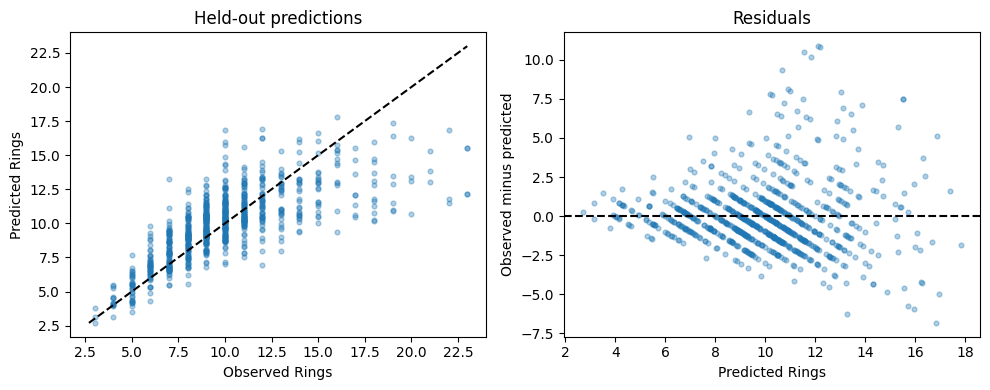

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_test, test_prediction, alpha=0.35, s=12)
limits = [min(y_test.min(), test_prediction.min()), max(y_test.max(), test_prediction.max())]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Observed Rings", ylabel="Predicted Rings", title="Held-out predictions")
axes[1].scatter(test_prediction, y_test - test_prediction, alpha=0.35, s=12)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted Rings", ylabel="Observed minus predicted", title="Residuals")
plt.tight_layout()
plt.show()

## 5. Save and reload the full pipeline

In [9]:
ARTIFACT_DIR = ROOT / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
model_path = ARTIFACT_DIR / "abalone_model.joblib"
joblib.dump(final_model, model_path)
loaded_model = joblib.load(model_path)
np.testing.assert_allclose(loaded_model.predict(X_test.head(5)), test_prediction[:5])
summary = {
    "selected_model": best_name,
    "data_sha256": DATA_SHA256,
    "split_seed": SEED,
    "rows": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "validation": comparison.reset_index().to_dict(orient="records"),
    "test": test_metrics,
    "test_baseline": baseline_metrics,
    "test_mae_improvement_pct": improvement,
}
(ARTIFACT_DIR / "step1_results.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Full pipeline saved; reloaded predictions match.")
# Verify an original, uncleaned input with zero height survives save/reload too.
zero_height_example = df.loc[df["Height"].eq(0)].drop(columns="Rings")
assert len(zero_height_example) > 0
np.testing.assert_allclose(
    loaded_model.predict(zero_height_example), final_model.predict(zero_height_example)
)
assert np.isfinite(loaded_model.predict(zero_height_example)).all()
print("Raw zero-height inputs are handled by the saved pipeline.")

Full pipeline saved; reloaded predictions match.
Raw zero-height inputs are handled by the saved pipeline.


## Interpretation and limits
The comparison tables are computed outputs, not assumed improvements. MAE is the
average absolute error in rings; RMSE penalizes large errors more strongly; higher
R² is better. The final pipeline accepts the original feature columns and converts zero Height
to missing values internally before applying its training-fitted preprocessing.
Sex is a category (I means infant), not an ordered numeric value.
Continuous ring predictions need not be integers. Do not report them as years.
This random split does not prove generalization to other populations or time periods.
There is no production API or retraining schedule yet; those are later project steps.
Load model files only from trusted sources. Generated models and MLflow artifacts are excluded from Git; the CSV is included in the repository.